# Experiment No. 5
# Aim: Ensemble Learning using Random Forest Classifier

 Step 1: Import required libraries

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [8]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1500)
pd.set_option("display.max_colwidth", 30)

Step 2: Load the dataset

In [9]:
df = pd.read_csv("car.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)


First 5 rows:
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc

Dataset Shape:
(1728, 7)

Column Names:
Index(['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class'], dtype='str')


Step 3: Preprocess the dataset

In [10]:
# Assign column names if the CSV has no header
if "buying" not in df.columns:
    df.columns = [
        "buying",
        "maint",
        "doors",
        "persons",
        "lug_boot",
        "safety",
        "class"
    ]

# Remove missing values
df.dropna(inplace=True)

print("\nDataset after preprocessing:")
print(df.head())



Dataset after preprocessing:
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc


C:\Users\tanis\AppData\Local\Temp\ipykernel_17160\2237302945.py:14: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


Step 4: Encode categorical columns

In [11]:
encoder = LabelEncoder()

for column in df.columns:
    df[column] = encoder.fit_transform(df[column])

print("\nEncoded Dataset:")
print(df.head())


Encoded Dataset:
   buying  maint  doors  persons  lug_boot  safety  class
0       3      3      0        0         2       1      2
1       3      3      0        0         2       2      2
2       3      3      0        0         2       0      2
3       3      3      0        0         1       1      2
4       3      3      0        0         1       2      2


Step 5: Select features and target

In [12]:
X = df.drop("class", axis=1)

y = df["class"]

Step 6: Split the dataset

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (1382, 6)
Testing Data Shape: (346, 6)


Step 7: Create Random Forest Classifier

In [14]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)


Step 8: Train the model

In [15]:
rf_model.fit(X_train, y_train)

print("\nRandom Forest Model Trained Successfully")


Random Forest Model Trained Successfully


 Step 9: Predict test data

In [16]:
y_pred = rf_model.predict(X_test)

print("\nPredicted Values:")
print(y_pred[:20])

print("\nActual Values:")
print(y_test[:20])


Predicted Values:
[1 2 2 2 0 2 2 0 2 2 2 2 2 2 3 2 0 2 2 2]

Actual Values:
1696    1
906     2
524     2
1080    2
593     0
169     2
928     2
389     0
1500    2
526     2
159     2
784     2
1072    2
461     2
1283    3
711     2
644     0
1438    2
273     2
145     2
Name: class, dtype: int64


Step 10: Calculate accuracy

In [17]:
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:")
print(accuracy * 100, "%")


Model Accuracy:
98.26589595375722 %


Step 11: Classification report

In [18]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred
    )
)



Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96        77
           1       0.93      0.93      0.93        14
           2       0.99      1.00      0.99       242
           3       1.00      0.92      0.96        13

    accuracy                           0.98       346
   macro avg       0.97      0.95      0.96       346
weighted avg       0.98      0.98      0.98       346



 Step 12: Confusion matrix

In [19]:
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)



Confusion Matrix:
[[ 73   1   3   0]
 [  1  13   0   0]
 [  0   0 242   0]
 [  1   0   0  12]]


Step 13: Visualize confusion matrix

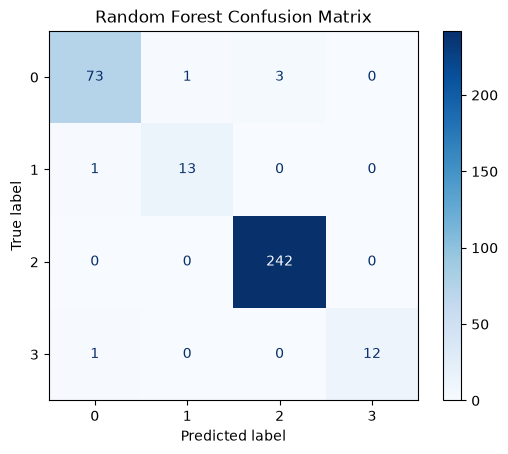

In [20]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(cmap="Blues")

plt.title("Random Forest Confusion Matrix")

plt.show()

Step 14: Feature importance


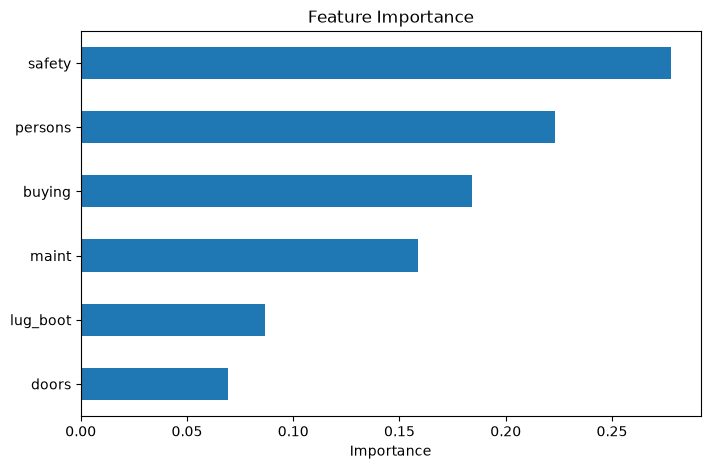

In [21]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
)

importance.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Feature Importance")

plt.xlabel("Importance")

plt.show()

Step 15: Predict safety of a new car

In [22]:

# Step 15: Predict safety of a new car

new_car = pd.DataFrame(
    [[2, 2, 1, 2, 1, 2]],
    columns=X.columns
)

# Predict car class
prediction = rf_model.predict(new_car)

# Decode predicted class using the original target encoder
class_encoder = LabelEncoder()
class_encoder.fit(
    pd.read_csv("car.csv").iloc[:, -1].astype(str)
)

print("\nPredicted Car Safety Class:")
print(class_encoder.inverse_transform(prediction)[0])



Predicted Car Safety Class:
acc
